In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
project_root = Path.cwd()

if not (project_root / "outputs").exists():
    project_root = project_root.parent

csv_path = project_root / "outputs" / "combined_baseline_results.csv"

results = pd.read_csv(csv_path)

print(results)

                       model               partition  n_samples  accuracy  \
0    Majority-class baseline  development_validation       3516  0.135950   
1    Majority-class baseline                ood_test       6231  0.091318   
2  PCA + Random Forest (RGB)  development_validation       3516  0.708476   
3  PCA + Random Forest (RGB)                ood_test       6231  0.448564   

   macro_f1  
0  0.023936  
1  0.016735  
2  0.691049  
3  0.436451  


In [5]:
rf_results = results[
    results["model"] == "PCA + Random Forest (RGB)"
]

print(rf_results)

                       model               partition  n_samples  accuracy  \
2  PCA + Random Forest (RGB)  development_validation       3516  0.708476   
3  PCA + Random Forest (RGB)                ood_test       6231  0.448564   

   macro_f1  
2  0.691049  
3  0.436451  


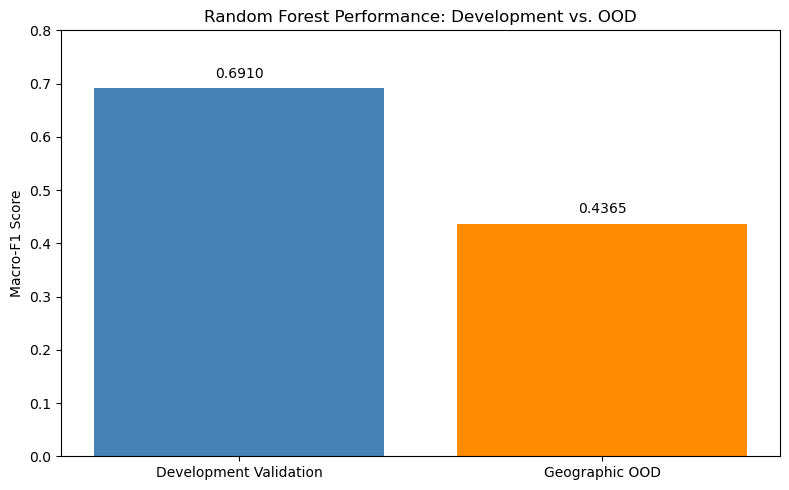

In [6]:
labels = ["Development Validation", "Geographic OOD"]
scores = rf_results.set_index("partition").loc[
    ["development_validation", "ood_test"], "macro_f1"
].values

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, scores, color=["steelblue", "darkorange"])

plt.title("Random Forest Performance: Development vs. OOD")
plt.ylabel("Macro-F1 Score")
plt.ylim(0, 0.8)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()

output_path = project_root / "outputs" / "baseline_f1_comparison.png"
plt.savefig(output_path, dpi=300)
plt.show()

In [7]:
development_f1 = scores[0]
ood_f1 = scores[1]

f1_drop = development_f1 - ood_f1

print(f"Development Macro-F1: {development_f1:.4f}")
print(f"OOD Macro-F1: {ood_f1:.4f}")
print(f"Macro-F1 Drop: {f1_drop:.4f}")

Development Macro-F1: 0.6910
OOD Macro-F1: 0.4365
Macro-F1 Drop: 0.2546


Preliminary Findings

The PCA + Random Forest baseline achieved a Macro-F1 score of 0.6910 on the development validation set and 0.4365 on the geographic OOD test set, representing a decrease of approximately 0.2546 points.

These results suggest reduced generalization performance on geographically different satellite images. However, the geographic partition requires further and more validation, so the findings remain preliminary.

In [8]:
class_path = project_root / "outputs" / "rgb_f1_gap_analysis.csv"

class_results = pd.read_csv(class_path)

print(class_results)

                  class  development_validation  ood_test   f1_drop
0               Pasture                0.771712  0.188925  0.582787
1  HerbaceousVegetation                0.729167  0.270394  0.458773
2            AnnualCrop                0.690476  0.338346  0.352130
3           Residential                0.709443  0.364419  0.345024
4                 River                0.578512  0.300231  0.278281
5            Industrial                0.863214  0.659987  0.203226
6               Highway                0.350877  0.183942  0.166936
7         PermanentCrop                0.401848  0.317003  0.084845
8                Forest                0.916865  0.864443  0.052422
9               SeaLake                0.898374  0.876821  0.021553


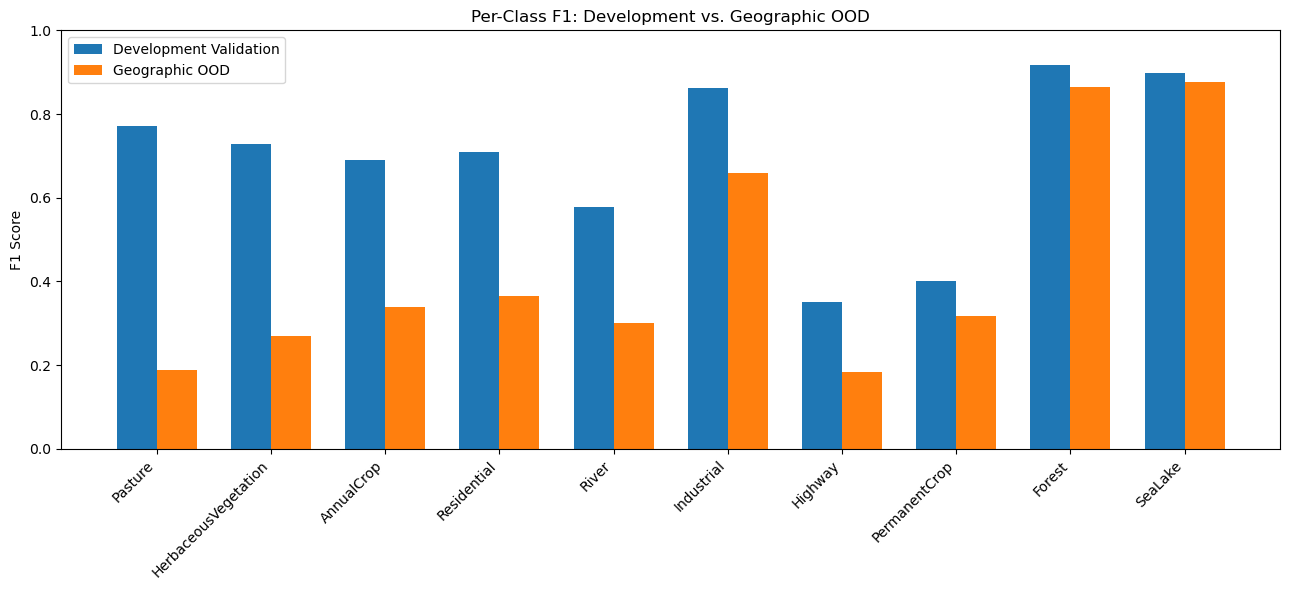

In [9]:
classes = class_results["class"]
development = class_results["development_validation"]
ood = class_results["ood_test"]

x = range(len(classes))
width = 0.35

plt.figure(figsize=(13, 6))

plt.bar(
    [i - width / 2 for i in x],
    development,
    width,
    label="Development Validation"
)

plt.bar(
    [i + width / 2 for i in x],
    ood,
    width,
    label="Geographic OOD"
)

plt.xticks(x, classes, rotation=45, ha="right")
plt.ylabel("F1 Score")
plt.title("Per-Class F1: Development vs. Geographic OOD")
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()

output_path = project_root / "outputs" / "per_class_f1_comparison.png"

plt.savefig(output_path, dpi=300)
plt.show()

In [10]:
sorted_results = class_results.sort_values(
    by="f1_drop",
    ascending=False
)

print(sorted_results[
    ["class", "development_validation", "ood_test", "f1_drop"]
])

                  class  development_validation  ood_test   f1_drop
0               Pasture                0.771712  0.188925  0.582787
1  HerbaceousVegetation                0.729167  0.270394  0.458773
2            AnnualCrop                0.690476  0.338346  0.352130
3           Residential                0.709443  0.364419  0.345024
4                 River                0.578512  0.300231  0.278281
5            Industrial                0.863214  0.659987  0.203226
6               Highway                0.350877  0.183942  0.166936
7         PermanentCrop                0.401848  0.317003  0.084845
8                Forest                0.916865  0.864443  0.052422
9               SeaLake                0.898374  0.876821  0.021553


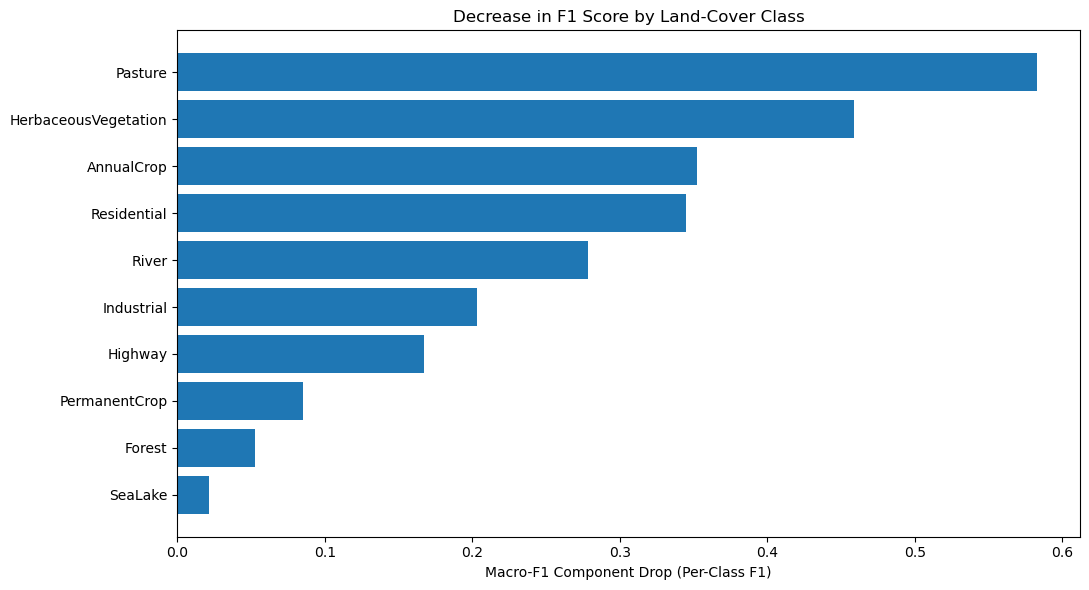

In [11]:
plt.figure(figsize=(11, 6))

plt.barh(
    sorted_results["class"],
    sorted_results["f1_drop"]
)

plt.xlabel("Macro-F1 Component Drop (Per-Class F1)")
plt.title("Decrease in F1 Score by Land-Cover Class")
plt.gca().invert_yaxis()

plt.tight_layout()

output_path = project_root / "outputs" / "per_class_f1_drop.png"

plt.savefig(output_path, dpi=300)
plt.show()

Per-Class Performance Analysis

The per-class F1 analysis shows that the PCA + Random Forest model experiences different levels of performance Decline across the ten land-cover categories.

Pasture experienced the largest decrease, with its F1 score dropping from approximately 0.7717 to 0.1889. Herbaceous Vegetation also showed a decline, from 0.7292 to 0.2704.

In comparison, Forest and Sea/Lake maintained relatively strong performance, with OOD F1 scores of approximately 0.8644 and 0.8768.

These findings suggest that certain land-cover categories are more sensitive to differences between the development and geographical data. However, further evaluation is needed to determine whether the differences arise from geographic variation, class distributions, or other factors.